# Program annotation panels across D0–D3

This notebook generates:

1. **One annotation panel per time point** (D0, D1, D2, and D3).
2. **One combined D0–D3 figure** with all time points stacked vertically.

Each time-point panel contains:

- **Regulator effects:** programs as rows and the union of the top three program-specific regulators as columns.
- **Marker-gene loadings:** programs as rows and representative marker genes as columns.
- **Motif enrichment:** motifs as rows and programs as columns, with a vector motif logo aligned to each motif row.

The combined figure uses one fixed, shared color scale for each data type across all time points:

- regulator effect: shared symmetric approximate log2-fold-change scale;
- marker genes: shared consensus cNMF-loading scale;
- motif enrichment: shared `-log10(q-value)` scale.

Motifs are selected as the top three motifs per program regardless of significance. Significance stars remain statistical annotations only. Heatmap cells are opaque vector rectangles for Illustrator compatibility, and motif logos are vector `logomaker` objects.


## Cell 1 — imports, paths, and settings

In [1]:

import os
import re
import json
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import h5py
import logomaker

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable


# ============================================================
# INPUT PATHS
# ============================================================

CONSENSUS_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/"
    "030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50."
    "spectra.k_50.dt_0_2.consensus.txt"
)

PROGRAM_ANNOT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/Programs_annotations.xlsx"
)

CNMF_WORKBOOK_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx"
)

ENHANCER_ENRICHMENT_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/"
    "analysis/2.tf_enrichment_in_programs/enhancer_enrichment_results.tsv"
)

CLUSTER_MAP_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/"
    "analysis/0.0.motif_id_annotation/tables/"
    "cluster_to_tf_motif_id_mapping.tsv"
)

MODISCO_H5_PATH = Path(
    "/oak/stanford/groups/engreitz/Users/opushkar/multiome_ipsc_ec_v0/archive/"
    "_results/compendium/modisco_compiled/modisco_compiled.h5"
)

OUTDIR = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/"
    "per_day_umaps"
)

SOURCE_DIR = OUTDIR / "_program_annotation_source"
LOGO_DIR = OUTDIR / "_program_annotation_logo_cache"  # retained for compatibility; vector logos do not use this cache

OUTDIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
LOGO_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# FIGURE SETTINGS
# ============================================================

DAYS_TO_PLOT = ["D0", "D1", "D2", "D3"]

N_TOP_REGULATORS = 3
N_TOP_MOTIFS = 3

REGULATOR_FDR_THRESHOLD = 0.05
MOTIF_QVAL_THRESHOLD = 0.05

# Used only for matching rows in the consensus spectra matrix.
# "auto" tests offsets 0, +1, -1 using known marker genes.
PROGRAM_OFFSET = "auto"

# Vector motif logos requested: draw logomaker logos directly in the figure.
# This is more Illustrator-editable than raster PNG logos, but the SVG/PDF can be heavier.
VECTOR_LOGOS = True

# Optional manual overrides if cluster mapping column auto-detection fails.
MANUAL_CLUSTER_ID_COL = None
MANUAL_MOTIF_NAME_COLS = None  # example: ["tf", "motif", "motif_name"]


# ------------------------------------------------------------------
# OUTPUT AND SHARED-SCALE SETTINGS
# ------------------------------------------------------------------

MAKE_PER_DAY_PANELS = True
MAKE_COMBINED_ALL_DAYS_FIGURE = True

# None = calculate from the union of all values plotted across D0-D3.
# Set a numeric value to force a manuscript-wide scale.
GLOBAL_REGULATOR_VMAX_OVERRIDE = None
GLOBAL_MARKER_VMAX_OVERRIDE = None
GLOBAL_MOTIF_VMAX_OVERRIDE = None

# Per-day figure geometry
PER_DAY_CELL_W_IN = 0.34
PER_DAY_CELL_H_IN = 0.34
PER_DAY_BLOCK_GAP_IN = 0.65
PER_DAY_MOTIF_NAME_W_IN = 1.15
PER_DAY_MOTIF_LOGO_W_IN = 1.55

# Combined figure geometry
COMBINED_CELL_W_IN = 0.30
COMBINED_CELL_H_IN = 0.30
COMBINED_DAY_GAP_IN = 0.85
COMBINED_HEADER_IN = 2.0
COMBINED_DAY_TOP_LABEL_SPACE_IN = 1.15
COMBINED_LEFT_MARGIN_IN = 3.3
COMBINED_RIGHT_MARGIN_IN = 0.9
COMBINED_BLOCK_GAP_IN = 0.65
COMBINED_MOTIF_NAME_W_IN = 1.10
COMBINED_MOTIF_LOGO_W_IN = 1.55

# Heatmap styling
HEATMAP_TILE_LINEWIDTH = 1.0
MISSING_TILE_COLOR = (0.95, 0.95, 0.95, 1.0)

# Colormaps requested
REGULATOR_CMAP = mpl.colormaps["RdBu_r"]
MARKER_CMAP = mpl.colormaps["Greys"]
MOTIF_CMAP = mpl.colormaps["Purples"]


# Illustrator-safe matplotlib defaults
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.transparent": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
})

print("Output directory:", OUTDIR)


Output directory: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps


## Cell 2 — metadata, regulator, and consensus-loading helper functions

In [2]:

# ============================================================
# HELPER FUNCTIONS
# ============================================================

def normalize_token(x):
    if pd.isna(x):
        return None
    x = str(x).strip().upper()
    x = re.sub(r"[^A-Z0-9]+", "", x)
    return x if x else None


def parse_program_num(x):
    m = re.search(r"(\d+)", str(x))
    return int(m.group(1)) if m else None


def split_feature_text(x):
    """
    Split annotation strings like:
      'TAL1/FLI1'
      'MECOM; NRP1; EFNB2'
      'L1TD1, DPPA4, TERF1, SOX2'
    into ordered feature tokens.
    """
    if pd.isna(x):
        return []

    txt = str(x).strip()
    if txt == "":
        return []

    parts = re.split(r"[;,/]", txt)
    cleaned = []
    seen = set()

    for part in parts:
        item = str(part).strip()
        item = re.sub(r"\([^)]*\)", "", item).strip()
        item = item.replace("?", "").strip()
        item = re.sub(r"\s+", " ", item)
        if item == "":
            continue

        # keep first token if there are comments
        item = item.split(" ")[0].strip()
        key = normalize_token(item)

        if key and key not in seen:
            cleaned.append(item)
            seen.add(key)

    return cleaned


def star_text(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def read_matrix_flex(path, index_col=0):
    attempts = [
        {"sep": "\t"},
        {"sep": r"\s+", "engine": "python"},
        {"sep": ","},
    ]
    errors = []

    for kwargs in attempts:
        try:
            df = pd.read_csv(path, index_col=index_col, **kwargs)
            df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
            if df.shape[0] >= 2 and df.shape[1] >= 2:
                return df
        except Exception as e:
            errors.append(str(e))

    raise ValueError(
        f"Could not read matrix: {path}\n" + "\n".join(errors)
    )


# ============================================================
# CONSENSUS LOADING MATRIX
# ============================================================

def read_consensus_matrix(path):
    """
    Return consensus matrix oriented as programs x genes.
    """
    mat = read_matrix_flex(path, index_col=0)

    # likely already ~50 x many_genes
    if mat.shape[0] > 200 and mat.shape[1] <= 200:
        mat = mat.T
    elif not (mat.shape[0] <= 200 and mat.shape[1] > 200):
        idx_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.index
        ])
        col_prog_frac = np.mean([
            bool(re.fullmatch(r"\s*(?:P|Program)?\s*\d+(?:\.0)?\s*", str(x), flags=re.I))
            for x in mat.columns
        ])
        if col_prog_frac > idx_prog_frac:
            mat = mat.T

    mat.columns = mat.columns.astype(str).str.strip()

    if mat.columns.duplicated().any():
        print("[warning] Duplicate gene columns found; collapsing by mean.")
        mat = mat.T.groupby(level=0).mean().T

    return mat.apply(pd.to_numeric, errors="coerce")


def build_program_row_lookup(consensus_df):
    lookup = {}
    for row_label in consensus_df.index:
        p = parse_program_num(row_label)
        if p is not None and p not in lookup:
            lookup[p] = row_label
    return lookup


def choose_program_offset(consensus_df, program_meta):
    """
    Use marker-gene loading consistency to choose offset 0 / +1 / -1.
    """
    if PROGRAM_OFFSET != "auto":
        print("Using manual PROGRAM_OFFSET =", PROGRAM_OFFSET)
        return int(PROGRAM_OFFSET)

    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    def score_offset(offset):
        vals = []
        for _, row in program_meta.iterrows():
            p = int(row["program_num"])
            marker_genes = row["marker_genes"]
            raw_p = p + offset
            if raw_p not in row_lookup:
                continue
            raw_row = row_lookup[raw_p]
            for gene in marker_genes:
                g = gene_lookup.get(normalize_token(gene))
                if g is None:
                    continue
                val = consensus_df.loc[raw_row, g]
                if pd.notna(val):
                    vals.append(float(val))
        if len(vals) == 0:
            return -np.inf
        return float(np.mean(vals))

    scores = {off: score_offset(off) for off in [0, 1, -1]}
    print("Consensus program-offset scores:", scores)
    best = max(scores, key=scores.get)
    print("Chosen consensus program offset:", best)
    return best


# ============================================================
# PROGRAM METADATA
# ============================================================

def load_program_metadata():
    """
    Merge:
      Programs_annotations.xlsx: program labels + representative genes
      cNMF Summary: automatic timepoint + top specific regulators columns
    """
    # Programs_annotations.xlsx
    annot = pd.read_excel(PROGRAM_ANNOT_PATH)
    annot.columns = [str(c).strip() for c in annot.columns]

    # Auto-detect expected annotation columns
    prog_col = next((c for c in annot.columns if "program" in c.lower() and "number" in c.lower()), annot.columns[0])
    name_col = next((c for c in annot.columns if c.lower() in ["name", "program name"]), None)
    rep_col = next((c for c in annot.columns if "representative" in c.lower() and "gene" in c.lower()), None)

    if name_col is None:
        name_col = next((c for c in annot.columns if "name" in c.lower()), None)
    if rep_col is None:
        rep_col = next((c for c in annot.columns if "gene" in c.lower()), None)

    if name_col is None or rep_col is None:
        raise ValueError(
            "Could not detect Name / Representative genes columns in Programs_annotations.xlsx. "
            f"Columns: {annot.columns.tolist()}"
        )

    annot = annot.rename(columns={
        prog_col: "program_raw",
        name_col: "program_name",
        rep_col: "representative_genes",
    })
    annot["program_num"] = annot["program_raw"].map(parse_program_num)
    annot = annot.dropna(subset=["program_num"]).copy()
    annot["program_num"] = annot["program_num"].astype(int)
    annot["program_name"] = annot["program_name"].astype(str).str.strip()
    annot["marker_genes"] = annot["representative_genes"].map(split_feature_text)

    # cNMF Summary
    summary = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Summary")
    summary.columns = [str(c).strip() for c in summary.columns]
    summary = summary.rename(columns={
        "program_name": "program_num",
        "Automatic Timepoint": "day",
    })
    summary["program_num"] = summary["program_num"].map(parse_program_num)
    summary = summary.dropna(subset=["program_num"]).copy()
    summary["program_num"] = summary["program_num"].astype(int)
    summary["day"] = summary["day"].astype(str).str.strip().str.upper()

    # merge
    meta = annot.merge(summary, on="program_num", how="left")

    # label
    meta["row_label"] = meta.apply(
        lambda r: f"P{int(r['program_num'])}  {r['program_name']}",
        axis=1
    )

    meta["marker_gene_source"] = "Programs_annotations.xlsx"
    meta = meta.sort_values(["day", "program_num"]).reset_index(drop=True)

    return meta


# ============================================================
# REGULATORS
# ============================================================

def load_perturbation_associations():
    pert = pd.read_excel(CNMF_WORKBOOK_PATH, sheet_name="Perturbation Association 1")
    pert.columns = [str(c).strip() for c in pert.columns]

    rename = {}
    if "target_name" in pert.columns:
        rename["target_name"] = "gene"
    if "program_name" in pert.columns:
        rename["program_name"] = "program"
    if "Sample" in pert.columns:
        rename["Sample"] = "day"
    if "approx_log2FC" in pert.columns:
        rename["approx_log2FC"] = "log2fc"
    if "adj_pval" in pert.columns:
        rename["adj_pval"] = "fdr"

    # Alternate spellings
    if "Perturbed gene" in pert.columns:
        rename["Perturbed gene"] = "gene"
    if "Gene Program" in pert.columns:
        rename["Gene Program"] = "program"
    if "adj.P.Val" in pert.columns:
        rename["adj.P.Val"] = "fdr"

    pert = pert.rename(columns=rename)

    required = ["gene", "program", "day", "log2fc", "fdr"]
    missing = [c for c in required if c not in pert.columns]
    if missing:
        raise ValueError(
            f"Perturbation Association 1 missing columns after rename: {missing}\n"
            f"Available columns: {pert.columns.tolist()}"
        )

    pert["program_num"] = pert["program"].map(parse_program_num)
    pert["day"] = pert["day"].astype(str).str.strip().str.upper()
    pert["gene_display"] = pert["gene"].astype(str).str.strip()
    pert["gene_key"] = pert["gene_display"].map(normalize_token)
    pert["log2fc"] = pd.to_numeric(pert["log2fc"], errors="coerce")
    pert["fdr"] = pd.to_numeric(pert["fdr"], errors="coerce")
    pert["is_sig"] = pert["fdr"] < REGULATOR_FDR_THRESHOLD

    return pert


def select_top_regulators_for_programs(program_meta_day, pert):
    """
    Top 3 specific regulators per program:
      1) use cNMF Summary column: 'Top 5 specific regulators (FDR<0.1) D2/D3'
      2) keep first N_TOP_REGULATORS from that list
      3) retrieve log2FC/FDR from Perturbation Association 1
    """
    day = str(program_meta_day["day"].iloc[0]).upper()
    col = f"Top 5 specific regulators (FDR<0.1) {day}"
    if col not in program_meta_day.columns:
        raise ValueError(f"Missing Summary column: {col}")

    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        regulator_list = split_feature_text(prow.get(col, ""))[:N_TOP_REGULATORS]
        selected_by_program[p] = regulator_list

        for rank, gene in enumerate(regulator_list, start=1):
            sub = pert.loc[
                (pert["program_num"] == p)
                & (pert["day"] == day)
                & (pert["gene_key"] == normalize_token(gene))
            ].copy()

            if len(sub) == 0:
                log2fc = np.nan
                fdr = np.nan
            else:
                # If duplicated, keep lowest FDR
                sub = sub.sort_values("fdr")
                log2fc = sub["log2fc"].iloc[0]
                fdr = sub["fdr"].iloc[0]

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "gene": gene,
                "log2fc": log2fc,
                "fdr": fdr,
                "signif_star": star_text(fdr),
            })

    selected_df = pd.DataFrame(rows)

    # union across programs in program order
    union = []
    seen = set()
    for p in program_meta_day["program_num"]:
        for gene in selected_by_program[int(p)]:
            key = normalize_token(gene)
            if key not in seen:
                union.append(gene)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_regulator_matrices(program_meta_day, regulator_union, pert):
    day = str(program_meta_day["day"].iloc[0]).upper()
    rows = [int(x) for x in program_meta_day["program_num"]]

    sub = pert.loc[pert["day"] == day].copy()

    effect_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="log2fc",
        aggfunc="first"
    )
    fdr_pivot = sub.pivot_table(
        index="program_num",
        columns="gene_key",
        values="fdr",
        aggfunc="min"
    )

    reg_keys = [normalize_token(g) for g in regulator_union]

    effect_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    fdr_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=float)
    star_mat = pd.DataFrame(index=rows, columns=regulator_union, dtype=object)

    for disp, key in zip(regulator_union, reg_keys):
        for p in rows:
            val = np.nan
            q = np.nan
            if p in effect_pivot.index and key in effect_pivot.columns:
                val = effect_pivot.loc[p, key]
            if p in fdr_pivot.index and key in fdr_pivot.columns:
                q = fdr_pivot.loc[p, key]

            effect_mat.loc[p, disp] = val
            fdr_mat.loc[p, disp] = q
            star_mat.loc[p, disp] = star_text(q)

    return effect_mat, fdr_mat, star_mat


## Cell 3 — marker-gene, motif, and vector-logo helper functions

In [3]:

# ============================================================
# MARKER GENES AND MOTIFS
# ============================================================

def select_marker_genes_for_programs(program_meta_day):
    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        genes = list(prow["marker_genes"])
        selected_by_program[p] = genes

        for rank, gene in enumerate(genes, start=1):
            rows.append({
                "day": prow["day"],
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "gene": gene,
                "source": prow["marker_gene_source"],
            })

    selected_df = pd.DataFrame(rows)

    union = []
    seen = set()
    for p in program_meta_day["program_num"]:
        for gene in selected_by_program[int(p)]:
            key = normalize_token(gene)
            if key not in seen:
                union.append(gene)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_marker_loading_matrix(program_meta_day, marker_union, consensus_df, consensus_offset):
    row_lookup = build_program_row_lookup(consensus_df)
    gene_lookup = {normalize_token(g): g for g in consensus_df.columns}

    rows = [int(x) for x in program_meta_day["program_num"]]
    mat = pd.DataFrame(index=rows, columns=marker_union, dtype=float)

    for p in rows:
        raw_p = p + consensus_offset
        if raw_p not in row_lookup:
            continue
        raw_row = row_lookup[raw_p]

        for gene in marker_union:
            g = gene_lookup.get(normalize_token(gene))
            if g is not None:
                mat.loc[p, gene] = consensus_df.loc[raw_row, g]

    return mat


def load_enhancer_enrichment():
    df = pd.read_csv(ENHANCER_ENRICHMENT_PATH, sep="\t")
    df["program_num"] = pd.to_numeric(df["program"], errors="coerce").astype("Int64")
    df["tf_display"] = df["tf"].astype(str).str.strip()
    df["tf_key"] = df["tf_display"].map(normalize_token)
    df["day"] = df["day"].astype(str).str.strip().str.upper()
    df["qval"] = pd.to_numeric(df["qval"], errors="coerce")
    df["neg_log10_qval"] = pd.to_numeric(df["neg_log10_qval"], errors="coerce")
    return df


def select_top_motifs_for_programs(program_meta_day, enrich):
    """
    Complete annotation-panel motif selection.

    For every program:
      - select the top N_TOP_MOTIFS motifs by q-value
      - do NOT require q < MOTIF_QVAL_THRESHOLD
      - keep non-significant motifs in the figure
      - use stars only to mark significance

    This guarantees that programs such as P7/P22 at D0 and P28 at D1
    still contribute motif columns/logos even when no motif passes q < 0.05.
    """
    selected_by_program = OrderedDict()
    rows = []

    for _, prow in program_meta_day.iterrows():
        p = int(prow["program_num"])
        day = str(prow["day"]).strip().upper()

        sub = enrich.loc[
            (enrich["program_num"] == p)
            & (enrich["day"] == day)
        ].copy()

        if sub.empty:
            selected_by_program[p] = []

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": np.nan,
                "motif": np.nan,
                "qval": np.nan,
                "neg_log10_qval": np.nan,
                "AUC": np.nan,
                "significant": False,
                "signif_star": "",
                "note": "no motif enrichment rows found",
            })

            continue

        # Make sure numeric columns are numeric
        sub["qval"] = pd.to_numeric(sub["qval"], errors="coerce")
        sub["neg_log10_qval"] = pd.to_numeric(sub["neg_log10_qval"], errors="coerce")

        if "AUC" in sub.columns:
            sub["AUC"] = pd.to_numeric(sub["AUC"], errors="coerce")
        else:
            sub["AUC"] = np.nan

        # Deduplicate motifs, keeping strongest q-value
        sub = (
            sub.sort_values(
                by=["qval", "neg_log10_qval", "AUC"],
                ascending=[True, False, False],
            )
            .drop_duplicates("tf_key", keep="first")
        )

        # Complete-panel behavior:
        # take top motifs regardless of significance
        top = sub.head(N_TOP_MOTIFS).copy()

        motifs = top["tf_display"].tolist()
        selected_by_program[p] = motifs

        for rank, (_, r) in enumerate(top.iterrows(), start=1):
            q = r["qval"]

            rows.append({
                "day": day,
                "program_num": p,
                "program_label": prow["row_label"],
                "rank_within_program": rank,
                "motif": r["tf_display"],
                "qval": q,
                "neg_log10_qval": r["neg_log10_qval"],
                "AUC": r.get("AUC", np.nan),
                "significant": bool(pd.notna(q) and q < MOTIF_QVAL_THRESHOLD),
                "signif_star": star_text(q),
                "note": "top motif by q-value; significance not required",
            })

    selected_df = pd.DataFrame(rows)

    # Union motifs across programs in program order
    union = []
    seen = set()

    for p in program_meta_day["program_num"]:
        for motif in selected_by_program.get(int(p), []):
            key = normalize_token(motif)

            if key not in seen:
                union.append(motif)
                seen.add(key)

    return selected_by_program, union, selected_df


def build_motif_matrices(program_meta_day, motif_union, enrich):
    rows = [int(x) for x in program_meta_day["program_num"]]
    day = str(program_meta_day["day"].iloc[0]).upper()
    sub = enrich.loc[enrich["day"] == day].copy()

    value_pivot = sub.pivot_table(
        index="program_num",
        columns="tf_key",
        values="neg_log10_qval",
        aggfunc="first"
    )
    qval_pivot = sub.pivot_table(
        index="program_num",
        columns="tf_key",
        values="qval",
        aggfunc="min"
    )

    motif_keys = [normalize_token(m) for m in motif_union]

    value_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=float)
    qval_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=float)
    star_mat = pd.DataFrame(index=rows, columns=motif_union, dtype=object)

    for disp, key in zip(motif_union, motif_keys):
        for p in rows:
            val = np.nan
            qv = np.nan

            if p in value_pivot.index and key in value_pivot.columns:
                val = value_pivot.loc[p, key]
            if p in qval_pivot.index and key in qval_pivot.columns:
                qv = qval_pivot.loc[p, key]

            value_mat.loc[p, disp] = val
            qval_mat.loc[p, disp] = qv
            star_mat.loc[p, disp] = star_text(qv)

    return value_mat, qval_mat, star_mat



# ============================================================
# MOTIF LOGOS: vector logomaker glyphs
# ============================================================

def infer_cluster_map_columns(df):
    if MANUAL_CLUSTER_ID_COL is not None:
        id_col = MANUAL_CLUSTER_ID_COL
    else:
        candidates = []
        for c in df.columns:
            lc = c.lower()
            numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
            if numeric_frac > 0.80 and re.search(r"(cluster|pattern|cid|id)", lc):
                candidates.append(c)
        if not candidates:
            for c in df.columns:
                numeric_frac = pd.to_numeric(df[c], errors="coerce").notna().mean()
                if numeric_frac > 0.80:
                    candidates.append(c)
        if len(candidates) == 0:
            raise ValueError(
                "Could not auto-detect cluster ID column. "
                f"Available columns: {list(df.columns)}"
            )
        id_col = candidates[0]

    if MANUAL_MOTIF_NAME_COLS is not None:
        name_cols = list(MANUAL_MOTIF_NAME_COLS)
    else:
        name_cols = []
        for c in df.columns:
            if c == id_col:
                continue
            if df[c].dtype == object:
                if not re.search(r"(path|file|url|image)", c.lower()):
                    name_cols.append(c)
        if len(name_cols) == 0:
            raise ValueError(
                "Could not auto-detect motif name columns. "
                f"Available columns: {list(df.columns)}"
            )

    return id_col, name_cols


def motif_alias_variants(name):
    base = str(name).strip()
    variants = set([base])

    cleaned = re.sub(r"_[0-9]+_$", "", base)
    variants.add(cleaned)

    for x in list(variants):
        variants.add(x.replace("_", ""))
        variants.add(x.replace("-", ""))
        variants.add(x.replace("/", ""))

    for part in re.split(r"[;/|]", base):
        part = part.strip()
        if part:
            variants.add(part)

    return [v for v in variants if v]


def build_cluster_lookup(cluster_map_df):
    id_col, name_cols = infer_cluster_map_columns(cluster_map_df)
    print("Cluster-map ID column:", id_col)
    print("Cluster-map motif columns:", name_cols)

    alias_to_cluster = {}

    for _, row in cluster_map_df.iterrows():
        cid = pd.to_numeric(row[id_col], errors="coerce")
        if pd.isna(cid):
            continue
        cid = int(cid)

        aliases = set()
        for c in name_cols:
            val = row[c]
            if pd.isna(val):
                continue
            aliases.add(str(val))
            for tok in re.split(r"[;,/|]", str(val)):
                tok = tok.strip()
                if tok:
                    aliases.add(tok)

        for alias in aliases:
            key = normalize_token(alias)
            if key and key not in alias_to_cluster:
                alias_to_cluster[key] = cid

    return alias_to_cluster


def best_cluster_for_motif(motif_name, alias_to_cluster):
    # exact match on normalized variants
    for variant in motif_alias_variants(motif_name):
        key = normalize_token(variant)
        if key in alias_to_cluster:
            return alias_to_cluster[key]

    # fuzzy prefix/containment match
    motif_keys = [normalize_token(v) for v in motif_alias_variants(motif_name)]
    motif_keys = [k for k in motif_keys if k]

    for mk in motif_keys:
        matches = []
        for alias_key, cid in alias_to_cluster.items():
            if mk.startswith(alias_key) or alias_key.startswith(mk):
                matches.append((len(alias_key), cid))
        if matches:
            matches = sorted(matches, reverse=True)
            return matches[0][1]

    return None


def load_cluster_cwms(h5_path):
    cluster_cwms = {}
    with h5py.File(h5_path, "r") as f:
        for cid_str in f["pos_patterns"].keys():
            cluster_cwms[int(cid_str)] = f["pos_patterns"][cid_str]["contrib_scores"][:]
    return cluster_cwms


def cwm_to_df(cwm):
    arr = np.asarray(cwm)
    if arr.ndim != 2:
        raise ValueError(f"Unexpected CWM ndim: {arr.ndim}")

    if arr.shape[1] == 4:
        mat = arr
    elif arr.shape[0] == 4:
        mat = arr.T
    else:
        raise ValueError(f"Unexpected CWM shape: {arr.shape}")

    return pd.DataFrame(mat, columns=list("ACGT"))


def resolve_logo_paths_for_motifs(motif_names):
    """
    Backward-compatible function name.

    Returns:
      motif_to_logo: dict motif -> {"type": "cwm", "cwm_df": DataFrame, "cluster_id": int}
                            or {"type": "text", "label": motif}
      motif_map_df:  metadata table with matched cluster IDs and status.

    Unlike the earlier raster version, this does NOT create PNG files.
    Logos are drawn as vector logomaker glyphs in add_logo_strip().
    """
    cluster_map_df = pd.read_csv(CLUSTER_MAP_PATH, sep="\t")
    alias_to_cluster = build_cluster_lookup(cluster_map_df)
    cluster_cwms = load_cluster_cwms(MODISCO_H5_PATH)

    motif_to_logo = {}
    motif_rows = []

    for motif in motif_names:
        cluster_id = best_cluster_for_motif(motif, alias_to_cluster)

        if cluster_id is not None and cluster_id in cluster_cwms:
            try:
                cwm_df = cwm_to_df(cluster_cwms[cluster_id])
                motif_to_logo[motif] = {
                    "type": "cwm",
                    "cwm_df": cwm_df,
                    "cluster_id": cluster_id,
                    "label": motif,
                }
                status = "vector_cwm"
            except Exception as e:
                print(f"[warning] Failed to load CWM for {motif} / cluster {cluster_id}: {e}")
                motif_to_logo[motif] = {"type": "text", "label": motif, "cluster_id": cluster_id}
                status = "text_fallback_after_cwm_error"
        else:
            motif_to_logo[motif] = {"type": "text", "label": motif, "cluster_id": cluster_id}
            status = "text_fallback_no_cluster"

        motif_rows.append({
            "motif": motif,
            "matched_cluster_id": cluster_id,
            "status": status,
        })

    motif_map_df = pd.DataFrame(motif_rows)
    return motif_to_logo, motif_map_df



## Cell 4 — plotting functions: motifs as rows and shared D0–D3 scales

In [4]:

# ============================================================
# PLOTTING FUNCTIONS
# ============================================================

def _finite_values(dataframes):
    vals = []
    for df in dataframes:
        if df is None or df.empty:
            continue
        arr = df.to_numpy(dtype=float)
        arr = arr[np.isfinite(arr)]
        if arr.size:
            vals.append(arr)
    if not vals:
        return np.array([], dtype=float)
    return np.concatenate(vals)


def compute_shared_color_scales(day_packages):
    """
    Compute one shared scale for each block using all values plotted across D0-D3.
    """
    regulator_values = _finite_values([
        pkg["reg_effect_mat"] for pkg in day_packages.values()
    ])
    marker_values = _finite_values([
        pkg["marker_loading_mat"] for pkg in day_packages.values()
    ])
    motif_values = _finite_values([
        pkg["motif_value_mat"] for pkg in day_packages.values()
    ])

    if regulator_values.size:
        regulator_vmax = float(np.max(np.abs(regulator_values)))
    else:
        regulator_vmax = 1.0

    if marker_values.size:
        marker_vmax = float(np.max(marker_values))
    else:
        marker_vmax = 1.0

    if motif_values.size:
        motif_vmax = float(np.max(motif_values))
    else:
        motif_vmax = 1.0

    if GLOBAL_REGULATOR_VMAX_OVERRIDE is not None:
        regulator_vmax = float(GLOBAL_REGULATOR_VMAX_OVERRIDE)
    if GLOBAL_MARKER_VMAX_OVERRIDE is not None:
        marker_vmax = float(GLOBAL_MARKER_VMAX_OVERRIDE)
    if GLOBAL_MOTIF_VMAX_OVERRIDE is not None:
        motif_vmax = float(GLOBAL_MOTIF_VMAX_OVERRIDE)

    regulator_vmax = max(regulator_vmax, 1e-12)
    marker_vmax = max(marker_vmax, 1e-12)
    motif_vmax = max(motif_vmax, 1e-12)

    scales = {
        "regulator_vmax": regulator_vmax,
        "marker_vmax": marker_vmax,
        "motif_vmax": motif_vmax,
        "regulator_norm": TwoSlopeNorm(
            vmin=-regulator_vmax,
            vcenter=0.0,
            vmax=regulator_vmax,
        ),
        "marker_norm": Normalize(vmin=0.0, vmax=marker_vmax),
        "motif_norm": Normalize(vmin=0.0, vmax=motif_vmax),
    }

    print("Shared color scales:")
    print(f"  regulator approximate log2FC: {-regulator_vmax:.4g} to {regulator_vmax:.4g}")
    print(f"  marker consensus loading: 0 to {marker_vmax:.4g}")
    print(f"  motif -log10(q): 0 to {motif_vmax:.4g}")

    return scales


def text_color_for_value(val, cmap, norm, na_color="#000000"):
    if pd.isna(val):
        return na_color

    rgba = cmap(norm(val))
    luminance = (
        0.2126 * rgba[0]
        + 0.7152 * rgba[1]
        + 0.0722 * rgba[2]
    )
    return "white" if luminance < 0.48 else "black"


def draw_rect_heatmap(
    ax,
    data_df,
    cmap,
    norm,
    xlabels,
    ylabels=None,
    stars_df=None,
    show_ylabels=True,
    xlabels_on_top=False,
    xlab_rotation=60,
    italic_x=False,
    xlab_fontsize=8,
    ylab_fontsize=8,
    star_fontsize=7,
    linewidth=HEATMAP_TILE_LINEWIDTH,
    missing_color=MISSING_TILE_COLOR,
):
    """
    Draw an Illustrator-safe heatmap using opaque vector rectangles.
    """
    n_rows, n_cols = data_df.shape
    vals = data_df.to_numpy(dtype=float)

    for i in range(n_rows):
        for j in range(n_cols):
            val = vals[i, j]

            if pd.isna(val):
                face = missing_color
            else:
                rgba = cmap(norm(val))
                face = (rgba[0], rgba[1], rgba[2], 1.0)

            ax.add_patch(
                Rectangle(
                    (j, i),
                    1,
                    1,
                    facecolor=face,
                    edgecolor="white",
                    linewidth=linewidth,
                )
            )

            if stars_df is not None:
                txt = stars_df.iloc[i, j]
                if isinstance(txt, str) and txt:
                    ax.text(
                        j + 0.5,
                        i + 0.5,
                        txt,
                        ha="center",
                        va="center",
                        fontsize=star_fontsize,
                        fontweight="bold",
                        color=text_color_for_value(val, cmap, norm),
                    )

    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_aspect("equal")

    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_xticklabels(
        xlabels,
        rotation=xlab_rotation,
        ha="right",
        rotation_mode="anchor",
        fontsize=xlab_fontsize,
        fontstyle="italic" if italic_x else "normal",
    )

    if xlabels_on_top:
        ax.xaxis.tick_top()
        ax.tick_params(
            axis="x",
            labeltop=True,
            labelbottom=False,
            pad=4,
        )
    else:
        ax.tick_params(
            axis="x",
            labeltop=False,
            labelbottom=True,
            pad=4,
        )

    ax.set_yticks(np.arange(n_rows) + 0.5)

    if show_ylabels:
        ax.set_yticklabels(ylabels, fontsize=ylab_fontsize)
    else:
        ax.set_yticklabels([""] * n_rows)

    ax.tick_params(axis="y", length=0, pad=4)
    ax.tick_params(axis="x", length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)


def add_horizontal_colorbar(
    fig,
    left,
    bottom,
    width,
    height,
    cmap,
    norm,
    label,
    ticksize=8,
    labelsize=9,
):
    cax = fig.add_axes([left, bottom, width, height])
    scalar = ScalarMappable(norm=norm, cmap=cmap)
    scalar.set_array([])

    cb = fig.colorbar(
        scalar,
        cax=cax,
        orientation="horizontal",
    )

    cb.outline.set_linewidth(0.8)
    cb.ax.tick_params(labelsize=ticksize, length=2)
    cb.set_label(label, fontsize=labelsize, labelpad=2)

    return cax, cb


def _draw_vector_logo(ax, motif, motif_to_logo, text_fontsize=6.5):
    logo_obj = motif_to_logo.get(
        motif,
        {"type": "text", "label": motif},
    )

    if logo_obj.get("type") == "cwm":
        try:
            logomaker.Logo(
                logo_obj["cwm_df"],
                ax=ax,
                color_scheme="classic",
                fade_below=0.0,
                shade_below=0.0,
                font_name="DejaVu Sans",
            )
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.set_title("")

            for spine in ax.spines.values():
                spine.set_visible(False)

            return

        except Exception as exc:
            print(f"[warning] Could not draw vector logo for {motif}: {exc}")

    ax.text(
        0.5,
        0.5,
        str(logo_obj.get("label", motif)),
        ha="center",
        va="center",
        fontsize=text_fontsize,
        fontweight="bold",
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")


def add_vector_logo_rows(
    fig,
    heat_ax,
    motif_names,
    motif_to_logo,
    name_width_fraction=0.42,
    total_left_width_fraction=0.15,
    label_fontsize=7.0,
):
    """
    Add motif name and vector logo immediately left of each motif heatmap row.

    Parameters use figure fractions. total_left_width_fraction is the total
    width reserved for both motif name and motif logo.
    """
    if len(motif_names) == 0:
        return []

    heat_pos = heat_ax.get_position()
    n_rows = len(motif_names)
    row_h = heat_pos.height / n_rows

    total_w = total_left_width_fraction
    name_w = total_w * name_width_fraction
    logo_w = total_w - name_w

    name_left = heat_pos.x0 - total_w
    logo_left = name_left + name_w

    logo_axes = []

    for i, motif in enumerate(motif_names):
        row_bottom = heat_pos.y1 - (i + 1) * row_h
        y_center = row_bottom + row_h / 2

        fig.text(
            logo_left - 0.005,
            y_center,
            str(motif),
            ha="right",
            va="center",
            fontsize=label_fontsize,
            fontweight="bold",
        )

        logo_ax = fig.add_axes([
            logo_left,
            row_bottom + row_h * 0.08,
            logo_w,
            row_h * 0.84,
        ])
        _draw_vector_logo(
            logo_ax,
            motif,
            motif_to_logo,
            text_fontsize=max(5.0, label_fontsize - 0.5),
        )

        logo_axes.append(logo_ax)

    return logo_axes


def _prepare_day_matrices(day_pkg):
    meta = day_pkg["meta"]
    program_nums = [int(x) for x in meta["program_num"]]
    row_labels = meta["row_label"].tolist()

    regulator_union = day_pkg["reg_union"]
    marker_union = day_pkg["marker_union"]
    motif_union = day_pkg["motif_union"]

    reg_mat = day_pkg["reg_effect_mat"].loc[
        program_nums,
        regulator_union,
    ]
    reg_star = day_pkg["reg_star_mat"].loc[
        program_nums,
        regulator_union,
    ]

    marker_mat = day_pkg["marker_loading_mat"].loc[
        program_nums,
        marker_union,
    ]

    # Transpose motif block:
    # rows = motifs, columns = programs.
    motif_mat = day_pkg["motif_value_mat"].loc[
        program_nums,
        motif_union,
    ].T

    motif_star = day_pkg["motif_star_mat"].loc[
        program_nums,
        motif_union,
    ].T

    motif_mat.columns = [f"P{p}" for p in program_nums]
    motif_star.columns = [f"P{p}" for p in program_nums]

    return {
        "program_nums": program_nums,
        "program_labels": row_labels,
        "regulator_union": regulator_union,
        "marker_union": marker_union,
        "motif_union": motif_union,
        "reg_mat": reg_mat,
        "reg_star": reg_star,
        "marker_mat": marker_mat,
        "motif_mat": motif_mat,
        "motif_star": motif_star,
    }


def make_day_panel_motifs_as_rows(
    day,
    day_pkg,
    shared_scales,
):
    """
    Make one day-specific panel using the shared D0-D3 color scales.
    """
    prepared = _prepare_day_matrices(day_pkg)

    n_prog = len(prepared["program_nums"])
    n_reg = len(prepared["regulator_union"])
    n_marker = len(prepared["marker_union"])
    n_motif = len(prepared["motif_union"])

    reg_w_in = max(2.2, n_reg * PER_DAY_CELL_W_IN)
    marker_w_in = max(2.2, n_marker * PER_DAY_CELL_W_IN)
    motif_heat_w_in = max(1.8, n_prog * PER_DAY_CELL_W_IN)

    max_rows = max(n_prog, n_motif, 1)
    heat_h_in = max_rows * PER_DAY_CELL_H_IN

    left_margin_in = 3.2
    right_margin_in = 0.8
    motif_side_in = (
        PER_DAY_MOTIF_NAME_W_IN
        + PER_DAY_MOTIF_LOGO_W_IN
    )

    fig_w = (
        left_margin_in
        + reg_w_in
        + PER_DAY_BLOCK_GAP_IN
        + marker_w_in
        + PER_DAY_BLOCK_GAP_IN
        + motif_side_in
        + motif_heat_w_in
        + right_margin_in
    )

    bottom_in = 1.8
    top_in = 1.9
    fig_h = bottom_in + heat_h_in + top_in

    fig = plt.figure(
        figsize=(fig_w, fig_h),
        facecolor="white",
    )

    def fx(x):
        return x / fig_w

    def fy(y):
        return y / fig_h

    reg_left = left_margin_in
    marker_left = (
        reg_left
        + reg_w_in
        + PER_DAY_BLOCK_GAP_IN
    )
    motif_heat_left = (
        marker_left
        + marker_w_in
        + PER_DAY_BLOCK_GAP_IN
        + motif_side_in
    )

    heat_top = bottom_in + heat_h_in

    reg_h = n_prog * PER_DAY_CELL_H_IN
    marker_h = n_prog * PER_DAY_CELL_H_IN
    motif_h = max(n_motif, 1) * PER_DAY_CELL_H_IN

    reg_bottom = heat_top - reg_h
    marker_bottom = heat_top - marker_h
    motif_bottom = heat_top - motif_h

    ax_reg = fig.add_axes([
        fx(reg_left),
        fy(reg_bottom),
        fx(reg_w_in),
        fy(reg_h),
    ])

    ax_marker = fig.add_axes([
        fx(marker_left),
        fy(marker_bottom),
        fx(marker_w_in),
        fy(marker_h),
    ])

    ax_motif = fig.add_axes([
        fx(motif_heat_left),
        fy(motif_bottom),
        fx(motif_heat_w_in),
        fy(motif_h),
    ])

    ylab_fs = max(7, min(12, 90 / max(n_prog, 1)))
    reg_x_fs = max(5, min(9, 90 / max(n_reg, 1)))
    marker_x_fs = max(5, min(9, 90 / max(n_marker, 1)))
    motif_prog_fs = max(7, min(10, 45 / max(n_prog, 1)))
    motif_name_fs = max(6, min(9, 70 / max(n_motif, 1)))
    star_fs = max(4, min(8, 70 / max(max(n_prog, n_motif), 1)))

    draw_rect_heatmap(
        ax_reg,
        prepared["reg_mat"],
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        xlabels=prepared["regulator_union"],
        ylabels=prepared["program_labels"],
        stars_df=prepared["reg_star"],
        show_ylabels=True,
        xlabels_on_top=False,
        xlab_rotation=58,
        italic_x=False,
        xlab_fontsize=reg_x_fs,
        ylab_fontsize=ylab_fs,
        star_fontsize=star_fs,
    )

    draw_rect_heatmap(
        ax_marker,
        prepared["marker_mat"],
        MARKER_CMAP,
        shared_scales["marker_norm"],
        xlabels=prepared["marker_union"],
        ylabels=prepared["program_labels"],
        stars_df=None,
        show_ylabels=False,
        xlabels_on_top=False,
        xlab_rotation=58,
        italic_x=True,
        xlab_fontsize=marker_x_fs,
        ylab_fontsize=ylab_fs,
        star_fontsize=star_fs,
    )

    draw_rect_heatmap(
        ax_motif,
        prepared["motif_mat"],
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        xlabels=[f"P{p}" for p in prepared["program_nums"]],
        ylabels=prepared["motif_union"],
        stars_df=prepared["motif_star"],
        show_ylabels=False,
        xlabels_on_top=True,
        xlab_rotation=0,
        italic_x=False,
        xlab_fontsize=motif_prog_fs,
        ylab_fontsize=motif_name_fs,
        star_fontsize=star_fs,
    )

    # Motif labels and logos are immediately left of motif rows.
    total_logo_fraction = fx(motif_side_in)
    add_vector_logo_rows(
        fig,
        ax_motif,
        prepared["motif_union"],
        day_pkg["motif_to_logo"],
        total_left_width_fraction=total_logo_fraction,
        label_fontsize=motif_name_fs,
    )

    # Block titles.
    title_y = heat_top + 0.72
    fig.text(
        fx(reg_left + reg_w_in / 2),
        fy(title_y),
        "Regulator effects",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )
    fig.text(
        fx(marker_left + marker_w_in / 2),
        fy(title_y),
        "Marker-gene loadings",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )
    fig.text(
        fx(motif_heat_left - motif_side_in / 2 + motif_heat_w_in / 2),
        fy(title_y),
        "Motif enrichment",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
    )

    # Per-day colorbars use the same shared scales as the combined figure.
    cbar_y = heat_top + 0.20
    cbar_h = 0.13

    add_horizontal_colorbar(
        fig,
        fx(reg_left),
        fy(cbar_y),
        fx(reg_w_in),
        fy(cbar_h),
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        "approx. log$_2$FC",
    )
    add_horizontal_colorbar(
        fig,
        fx(marker_left),
        fy(cbar_y),
        fx(marker_w_in),
        fy(cbar_h),
        MARKER_CMAP,
        shared_scales["marker_norm"],
        "consensus cNMF loading",
    )
    add_horizontal_colorbar(
        fig,
        fx(motif_heat_left - motif_side_in),
        fy(cbar_y),
        fx(motif_side_in + motif_heat_w_in),
        fy(cbar_h),
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        "$-\\log_{10}$(q-value)",
    )

    day_title = {
        "D0": "Day 0",
        "D1": "Day 1",
        "D2": "Day 2",
        "D3": "Day 3",
    }.get(day, str(day))

    fig.text(
        fx(0.25),
        fy(fig_h - 0.28),
        day_title,
        ha="left",
        va="top",
        fontsize=23,
        fontweight="bold",
    )

    fig.text(
        fx(reg_left),
        fy(0.28),
        "* < 0.05;  ** < 0.01;  *** < 0.001. "
        "Top three motifs per program are shown regardless of significance.",
        fontsize=8.5,
        color="#444444",
        ha="left",
        va="bottom",
    )

    outstem = OUTDIR / f"Program_annotation_panel_{day}_motifs_as_rows"

    for extension in ["svg", "pdf", "png"]:
        save_kwargs = {
            "bbox_inches": "tight",
            "facecolor": "white",
            "transparent": False,
        }

        if extension == "png":
            save_kwargs["dpi"] = 600

        fig.savefig(
            outstem.with_suffix(f".{extension}"),
            **save_kwargs,
        )

    plt.show()
    plt.close(fig)

    return outstem


def make_combined_all_days_figure(
    day_packages,
    days,
    shared_scales,
):
    """
    Stack D0-D3 vertically and use exactly one shared colorbar for each block.
    Motif blocks are transposed: motifs are rows and programs are columns.
    """
    valid_days = [
        day for day in days
        if day in day_packages
    ]

    if not valid_days:
        raise ValueError("No valid day packages were available.")

    prepared_by_day = {
        day: _prepare_day_matrices(day_packages[day])
        for day in valid_days
    }

    max_reg_cols = max(
        len(x["regulator_union"])
        for x in prepared_by_day.values()
    )
    max_marker_cols = max(
        len(x["marker_union"])
        for x in prepared_by_day.values()
    )
    max_program_cols = max(
        len(x["program_nums"])
        for x in prepared_by_day.values()
    )

    reg_w_in = max(2.4, max_reg_cols * COMBINED_CELL_W_IN)
    marker_w_in = max(2.4, max_marker_cols * COMBINED_CELL_W_IN)
    motif_heat_w_in = max(1.8, max_program_cols * COMBINED_CELL_W_IN)

    motif_side_in = (
        COMBINED_MOTIF_NAME_W_IN
        + COMBINED_MOTIF_LOGO_W_IN
    )

    fig_w = (
        COMBINED_LEFT_MARGIN_IN
        + reg_w_in
        + COMBINED_BLOCK_GAP_IN
        + marker_w_in
        + COMBINED_BLOCK_GAP_IN
        + motif_side_in
        + motif_heat_w_in
        + COMBINED_RIGHT_MARGIN_IN
    )

    day_layouts = {}
    total_day_height = 0.0

    for day in valid_days:
        prep = prepared_by_day[day]
        max_rows = max(
            len(prep["program_nums"]),
            len(prep["motif_union"]),
            1,
        )

        heat_h = max_rows * COMBINED_CELL_H_IN
        band_h = (
            COMBINED_DAY_TOP_LABEL_SPACE_IN
            + heat_h
        )

        day_layouts[day] = {
            "max_rows": max_rows,
            "heat_h": heat_h,
            "band_h": band_h,
        }

        total_day_height += band_h

    total_day_height += (
        COMBINED_DAY_GAP_IN
        * (len(valid_days) - 1)
    )

    bottom_margin_in = 0.9
    fig_h = (
        bottom_margin_in
        + total_day_height
        + COMBINED_HEADER_IN
        + 0.35
    )

    fig = plt.figure(
        figsize=(fig_w, fig_h),
        facecolor="white",
    )

    def fx(x):
        return x / fig_w

    def fy(y):
        return y / fig_h

    reg_left = COMBINED_LEFT_MARGIN_IN
    marker_left = (
        reg_left
        + reg_w_in
        + COMBINED_BLOCK_GAP_IN
    )
    motif_heat_left = (
        marker_left
        + marker_w_in
        + COMBINED_BLOCK_GAP_IN
        + motif_side_in
    )

    # ------------------------------------------------------------------
    # One global title and one shared colorbar per data type.
    # ------------------------------------------------------------------
    header_bottom = fig_h - COMBINED_HEADER_IN

    fig.text(
        fx(0.25),
        fy(fig_h - 0.20),
        "Program annotations across differentiation",
        ha="left",
        va="top",
        fontsize=24,
        fontweight="bold",
    )

    block_title_y = fig_h - 0.66
    cbar_y = fig_h - 1.13
    cbar_h = 0.14

    fig.text(
        fx(reg_left + reg_w_in / 2),
        fy(block_title_y),
        "Regulator effects",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )
    fig.text(
        fx(marker_left + marker_w_in / 2),
        fy(block_title_y),
        "Marker-gene loadings",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )
    fig.text(
        fx(
            motif_heat_left
            - motif_side_in
            + (motif_side_in + motif_heat_w_in) / 2
        ),
        fy(block_title_y),
        "Motif enrichment",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )

    add_horizontal_colorbar(
        fig,
        fx(reg_left),
        fy(cbar_y),
        fx(reg_w_in),
        fy(cbar_h),
        REGULATOR_CMAP,
        shared_scales["regulator_norm"],
        "approx. log$_2$FC",
        ticksize=8,
        labelsize=9,
    )
    add_horizontal_colorbar(
        fig,
        fx(marker_left),
        fy(cbar_y),
        fx(marker_w_in),
        fy(cbar_h),
        MARKER_CMAP,
        shared_scales["marker_norm"],
        "consensus cNMF loading",
        ticksize=8,
        labelsize=9,
    )
    add_horizontal_colorbar(
        fig,
        fx(motif_heat_left - motif_side_in),
        fy(cbar_y),
        fx(motif_side_in + motif_heat_w_in),
        fy(cbar_h),
        MOTIF_CMAP,
        shared_scales["motif_norm"],
        "$-\\log_{10}$(q-value)",
        ticksize=8,
        labelsize=9,
    )

    fig.text(
        fx(reg_left),
        fy(fig_h - 1.54),
        "* < 0.05;  ** < 0.01;  *** < 0.001. "
        "Motifs shown regardless of significance.",
        fontsize=9,
        color="#444444",
        ha="left",
        va="top",
    )

    # ------------------------------------------------------------------
    # Draw day bands from top to bottom.
    # ------------------------------------------------------------------
    current_top = header_bottom - 0.10

    for day_index, day in enumerate(valid_days):
        prep = prepared_by_day[day]
        layout = day_layouts[day]

        n_prog = len(prep["program_nums"])
        n_reg = len(prep["regulator_union"])
        n_marker = len(prep["marker_union"])
        n_motif = len(prep["motif_union"])

        heat_h = layout["heat_h"]
        band_h = layout["band_h"]

        band_bottom = current_top - band_h
        heat_top = current_top - COMBINED_DAY_TOP_LABEL_SPACE_IN

        reg_h = max(n_prog, 1) * COMBINED_CELL_H_IN
        marker_h = max(n_prog, 1) * COMBINED_CELL_H_IN
        motif_h = max(n_motif, 1) * COMBINED_CELL_H_IN

        reg_bottom = heat_top - reg_h
        marker_bottom = heat_top - marker_h
        motif_bottom = heat_top - motif_h

        # Use actual number of columns so cells remain square.
        reg_actual_w = max(
            COMBINED_CELL_W_IN,
            n_reg * COMBINED_CELL_W_IN,
        )
        marker_actual_w = max(
            COMBINED_CELL_W_IN,
            n_marker * COMBINED_CELL_W_IN,
        )
        motif_actual_w = max(
            COMBINED_CELL_W_IN,
            n_prog * COMBINED_CELL_W_IN,
        )

        ax_reg = fig.add_axes([
            fx(reg_left),
            fy(reg_bottom),
            fx(reg_actual_w),
            fy(reg_h),
        ])

        ax_marker = fig.add_axes([
            fx(marker_left),
            fy(marker_bottom),
            fx(marker_actual_w),
            fy(marker_h),
        ])

        ax_motif = fig.add_axes([
            fx(motif_heat_left),
            fy(motif_bottom),
            fx(motif_actual_w),
            fy(motif_h),
        ])

        ylab_fs = max(6.0, min(10.0, 70 / max(n_prog, 1)))
        reg_x_fs = max(4.5, min(8.0, 80 / max(n_reg, 1)))
        marker_x_fs = max(4.5, min(8.0, 80 / max(n_marker, 1)))
        motif_prog_fs = max(6.0, min(8.5, 38 / max(n_prog, 1)))
        motif_name_fs = max(5.5, min(8.0, 55 / max(n_motif, 1)))
        star_fs = max(
            4.0,
            min(7.0, 50 / max(n_prog, n_motif, 1)),
        )

        draw_rect_heatmap(
            ax_reg,
            prep["reg_mat"],
            REGULATOR_CMAP,
            shared_scales["regulator_norm"],
            xlabels=prep["regulator_union"],
            ylabels=prep["program_labels"],
            stars_df=prep["reg_star"],
            show_ylabels=True,
            xlabels_on_top=True,
            xlab_rotation=58,
            italic_x=False,
            xlab_fontsize=reg_x_fs,
            ylab_fontsize=ylab_fs,
            star_fontsize=star_fs,
        )

        draw_rect_heatmap(
            ax_marker,
            prep["marker_mat"],
            MARKER_CMAP,
            shared_scales["marker_norm"],
            xlabels=prep["marker_union"],
            ylabels=prep["program_labels"],
            stars_df=None,
            show_ylabels=False,
            xlabels_on_top=True,
            xlab_rotation=58,
            italic_x=True,
            xlab_fontsize=marker_x_fs,
            ylab_fontsize=ylab_fs,
            star_fontsize=star_fs,
        )

        draw_rect_heatmap(
            ax_motif,
            prep["motif_mat"],
            MOTIF_CMAP,
            shared_scales["motif_norm"],
            xlabels=[f"P{p}" for p in prep["program_nums"]],
            ylabels=prep["motif_union"],
            stars_df=prep["motif_star"],
            show_ylabels=False,
            xlabels_on_top=True,
            xlab_rotation=0,
            italic_x=False,
            xlab_fontsize=motif_prog_fs,
            ylab_fontsize=motif_name_fs,
            star_fontsize=star_fs,
        )

        # Logos and motif names aligned to motif rows.
        add_vector_logo_rows(
            fig,
            ax_motif,
            prep["motif_union"],
            day_packages[day]["motif_to_logo"],
            total_left_width_fraction=fx(motif_side_in),
            label_fontsize=motif_name_fs,
        )

        # Day label.
        day_title = {
            "D0": "Day 0",
            "D1": "Day 1",
            "D2": "Day 2",
            "D3": "Day 3",
        }.get(day, str(day))

        fig.text(
            fx(0.24),
            fy(heat_top + 0.42),
            day_title,
            ha="left",
            va="center",
            fontsize=18,
            fontweight="bold",
        )

        # Light separator below each day except the last.
        if day_index < len(valid_days) - 1:
            separator_y = band_bottom - COMBINED_DAY_GAP_IN / 2

            separator_ax = fig.add_axes([
                fx(0.20),
                fy(separator_y),
                fx(fig_w - 0.40),
                0.001,
            ])
            separator_ax.axhline(
                0,
                color="#D6D6D6",
                linewidth=0.8,
            )
            separator_ax.axis("off")

        current_top = (
            band_bottom
            - COMBINED_DAY_GAP_IN
        )

    outstem = (
        OUTDIR
        / "Program_annotation_D0_D1_D2_D3_combined_motifs_as_rows"
    )

    for extension in ["svg", "pdf", "png"]:
        save_kwargs = {
            "bbox_inches": "tight",
            "facecolor": "white",
            "transparent": False,
        }

        if extension == "png":
            save_kwargs["dpi"] = 600

        fig.savefig(
            outstem.with_suffix(f".{extension}"),
            **save_kwargs,
        )

    plt.show()
    plt.close(fig)

    return outstem


## Cell 5 — load data, select features, and save source tables

In [5]:

# ============================================================
# LOAD DATA, SELECT FEATURES, SAVE SOURCE TABLES
# ============================================================

program_meta = load_program_metadata()
pert = load_perturbation_associations()
enh = load_enhancer_enrichment()
consensus = read_consensus_matrix(CONSENSUS_PATH)

print("Program metadata:", program_meta.shape)
print("Perturb associations:", pert.shape)
print("Enhancer enrichment:", enh.shape)
print("Consensus matrix:", consensus.shape)

# choose program offset for consensus matrix
consensus_offset = choose_program_offset(consensus, program_meta)

program_meta.to_csv(SOURCE_DIR / "program_metadata_merged.csv", index=False)

day_packages = {}

for day in DAYS_TO_PLOT:
    meta_day = (
        program_meta.loc[program_meta["day"] == day]
        .sort_values("program_num")
        .reset_index(drop=True)
    )

    if meta_day.empty:
        print(f"[warning] no programs found for {day}")
        continue

    # regulators
    reg_by_prog, reg_union, reg_selected_df = select_top_regulators_for_programs(meta_day, pert)
    reg_effect_mat, reg_fdr_mat, reg_star_mat = build_regulator_matrices(meta_day, reg_union, pert)

    # markers
    marker_by_prog, marker_union, marker_selected_df = select_marker_genes_for_programs(meta_day)
    marker_loading_mat = build_marker_loading_matrix(meta_day, marker_union, consensus, consensus_offset)

    # motifs
    motif_by_prog, motif_union, motif_selected_df = select_top_motifs_for_programs(meta_day, enh)
    motif_value_mat, motif_qval_mat, motif_star_mat = build_motif_matrices(meta_day, motif_union, enh)

    # logos
    motif_to_logo, motif_logo_map_df = resolve_logo_paths_for_motifs(motif_union)

    day_packages[day] = {
        "meta": meta_day,
        "reg_union": reg_union,
        "reg_selected_df": reg_selected_df,
        "reg_effect_mat": reg_effect_mat,
        "reg_fdr_mat": reg_fdr_mat,
        "reg_star_mat": reg_star_mat,
        "marker_union": marker_union,
        "marker_selected_df": marker_selected_df,
        "marker_loading_mat": marker_loading_mat,
        "motif_union": motif_union,
        "motif_selected_df": motif_selected_df,
        "motif_value_mat": motif_value_mat,
        "motif_qval_mat": motif_qval_mat,
        "motif_star_mat": motif_star_mat,
        "motif_to_logo": motif_to_logo,
        "motif_logo_map_df": motif_logo_map_df,
    }

    # Save source tables
    prefix = SOURCE_DIR / f"{day}"

    meta_day.to_csv(f"{prefix}_programs.csv", index=False)

    reg_selected_df.to_csv(f"{prefix}_selected_regulators.csv", index=False)
    reg_effect_mat.to_csv(f"{prefix}_regulator_effect_matrix.csv", index_label="program_num")
    reg_fdr_mat.to_csv(f"{prefix}_regulator_fdr_matrix.csv", index_label="program_num")
    reg_star_mat.to_csv(f"{prefix}_regulator_star_matrix.csv", index_label="program_num")

    marker_selected_df.to_csv(f"{prefix}_selected_marker_genes.csv", index=False)
    marker_loading_mat.to_csv(f"{prefix}_marker_loading_matrix.csv", index_label="program_num")

    motif_selected_df.to_csv(f"{prefix}_selected_motifs.csv", index=False)
    motif_value_mat.to_csv(f"{prefix}_motif_enrichment_matrix.csv", index_label="program_num")
    motif_qval_mat.to_csv(f"{prefix}_motif_qval_matrix.csv", index_label="program_num")
    motif_star_mat.to_csv(f"{prefix}_motif_star_matrix.csv", index_label="program_num")
    motif_logo_map_df.to_csv(f"{prefix}_motif_logo_map.csv", index=False)

    print(f"\n=== {day} ===")
    print("Programs:", meta_day["program_num"].tolist())
    print("Selected regulators:", len(reg_union))
    print("Selected marker genes:", len(marker_union))
    print("Selected motifs:", len(motif_union))


# ============================================================
# SHARED COLOR SCALES ACROSS D0-D3
# ============================================================

shared_scales = compute_shared_color_scales(day_packages)

shared_scale_values = {
    "regulator_vmin": -shared_scales["regulator_vmax"],
    "regulator_vmax": shared_scales["regulator_vmax"],
    "marker_vmin": 0.0,
    "marker_vmax": shared_scales["marker_vmax"],
    "motif_vmin": 0.0,
    "motif_vmax": shared_scales["motif_vmax"],
}

with open(SOURCE_DIR / "shared_color_scales_D0_D3.json", "w") as handle:
    json.dump(shared_scale_values, handle, indent=2)

# Save config
config_used = {
    "CONSENSUS_PATH": str(CONSENSUS_PATH),
    "PROGRAM_ANNOT_PATH": str(PROGRAM_ANNOT_PATH),
    "CNMF_WORKBOOK_PATH": str(CNMF_WORKBOOK_PATH),
    "ENHANCER_ENRICHMENT_PATH": str(ENHANCER_ENRICHMENT_PATH),
    "CLUSTER_MAP_PATH": str(CLUSTER_MAP_PATH),
    "MODISCO_H5_PATH": str(MODISCO_H5_PATH),
    "PROGRAM_OFFSET": PROGRAM_OFFSET,
    "consensus_offset_chosen": consensus_offset,
    "N_TOP_REGULATORS": N_TOP_REGULATORS,
    "N_TOP_MOTIFS": N_TOP_MOTIFS,
    "REGULATOR_FDR_THRESHOLD": REGULATOR_FDR_THRESHOLD,
    "MOTIF_QVAL_THRESHOLD": MOTIF_QVAL_THRESHOLD,
    "VECTOR_LOGOS": VECTOR_LOGOS,
    "MAKE_PER_DAY_PANELS": MAKE_PER_DAY_PANELS,
    "MAKE_COMBINED_ALL_DAYS_FIGURE": MAKE_COMBINED_ALL_DAYS_FIGURE,
    "shared_color_scales": shared_scale_values,
}

with open(SOURCE_DIR / "figure_config_used.json", "w") as f:
    json.dump(config_used, f, indent=2)

print("\nSource tables written to:", SOURCE_DIR)
print("Vector logos will be embedded directly in SVG/PDF.")
print("Shared color scales written to:", SOURCE_DIR / "shared_color_scales_D0_D3.json")


Program metadata: (17, 42)
Perturb associations: (59800, 13)
Enhancer enrichment: (13906, 16)
Consensus matrix: (50, 17538)
Consensus program-offset scores: {0: 5.070201602456141e-05, 1: 0.0014924993410526314, -1: 5.3358765333333336e-05}
Chosen consensus program offset: 1
Cluster-map ID column: cluster_id
Cluster-map motif columns: ['days_present', 'posneg', 'annotation_name0', 'annotation_names', 'TFs', 'tf_motif_id', 'expressed_TFs_d0', 'expressed_TFs_d1', 'expressed_TFs_d2', 'expressed_TFs_d3']

=== D0 ===
Programs: [7, 22, 29]
Selected regulators: 9
Selected marker genes: 9
Selected motifs: 8
Cluster-map ID column: cluster_id
Cluster-map motif columns: ['days_present', 'posneg', 'annotation_name0', 'annotation_names', 'TFs', 'tf_motif_id', 'expressed_TFs_d0', 'expressed_TFs_d1', 'expressed_TFs_d2', 'expressed_TFs_d3']

=== D1 ===
Programs: [13, 28, 30, 48]
Selected regulators: 10
Selected marker genes: 8
Selected motifs: 7
Cluster-map ID column: cluster_id
Cluster-map motif columns

## Cell 6 — render per-day panels and the combined D0–D3 figure

Rendering per-day panels with motifs as rows...


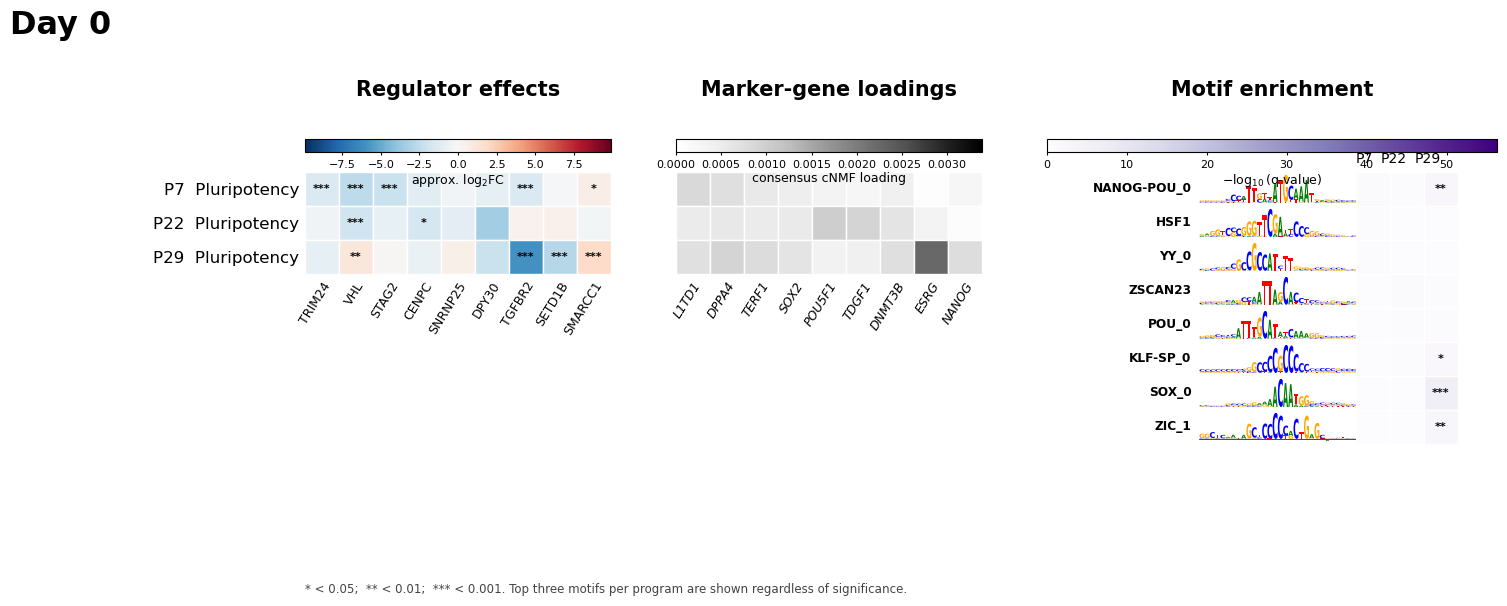

Saved D0:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0_motifs_as_rows.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0_motifs_as_rows.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D0_motifs_as_rows.png


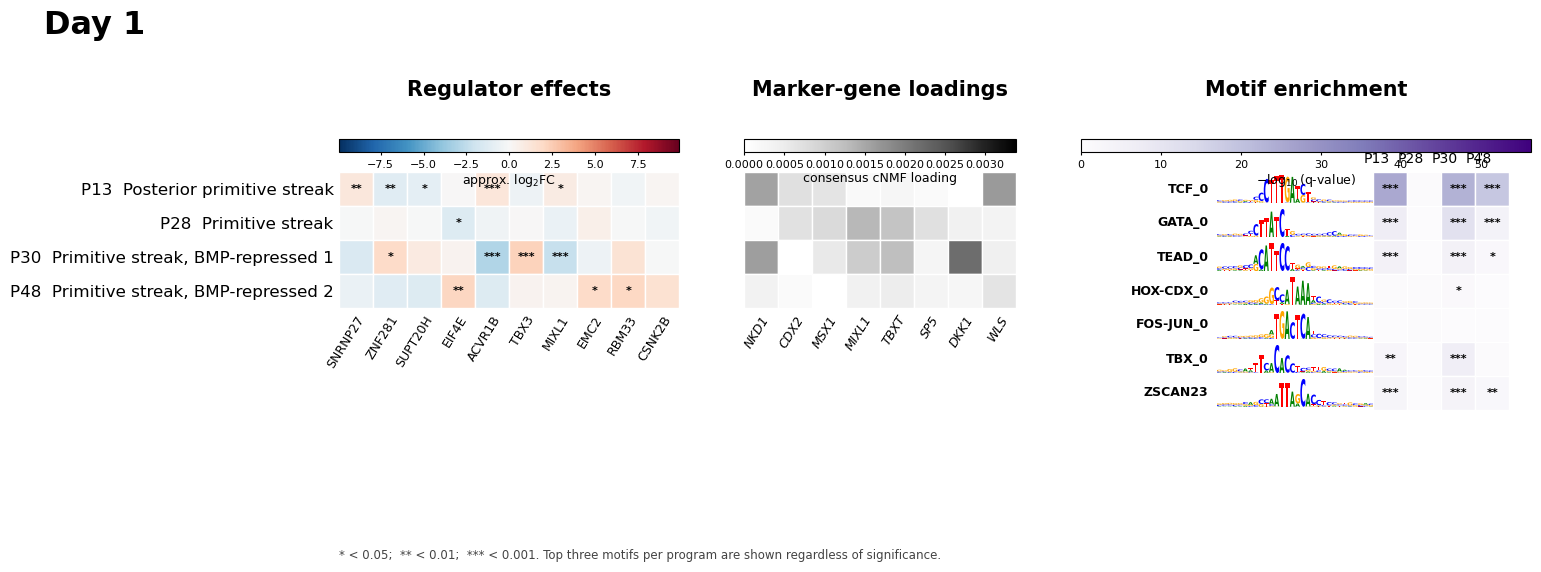

Saved D1:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1_motifs_as_rows.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1_motifs_as_rows.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D1_motifs_as_rows.png


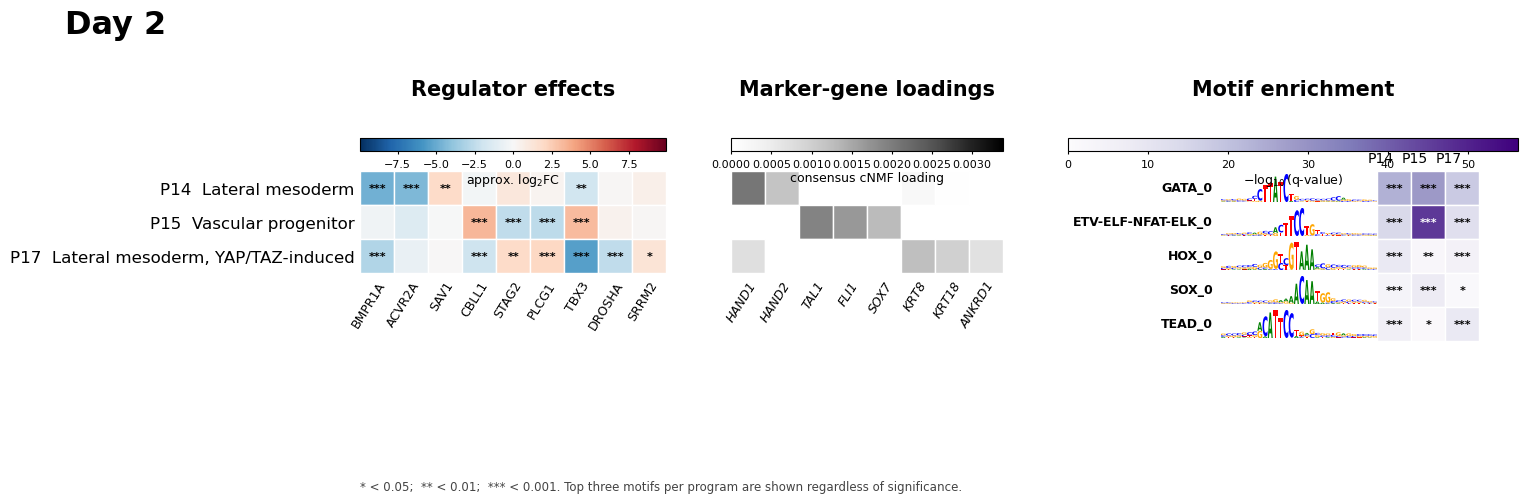

Saved D2:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2_motifs_as_rows.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2_motifs_as_rows.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D2_motifs_as_rows.png


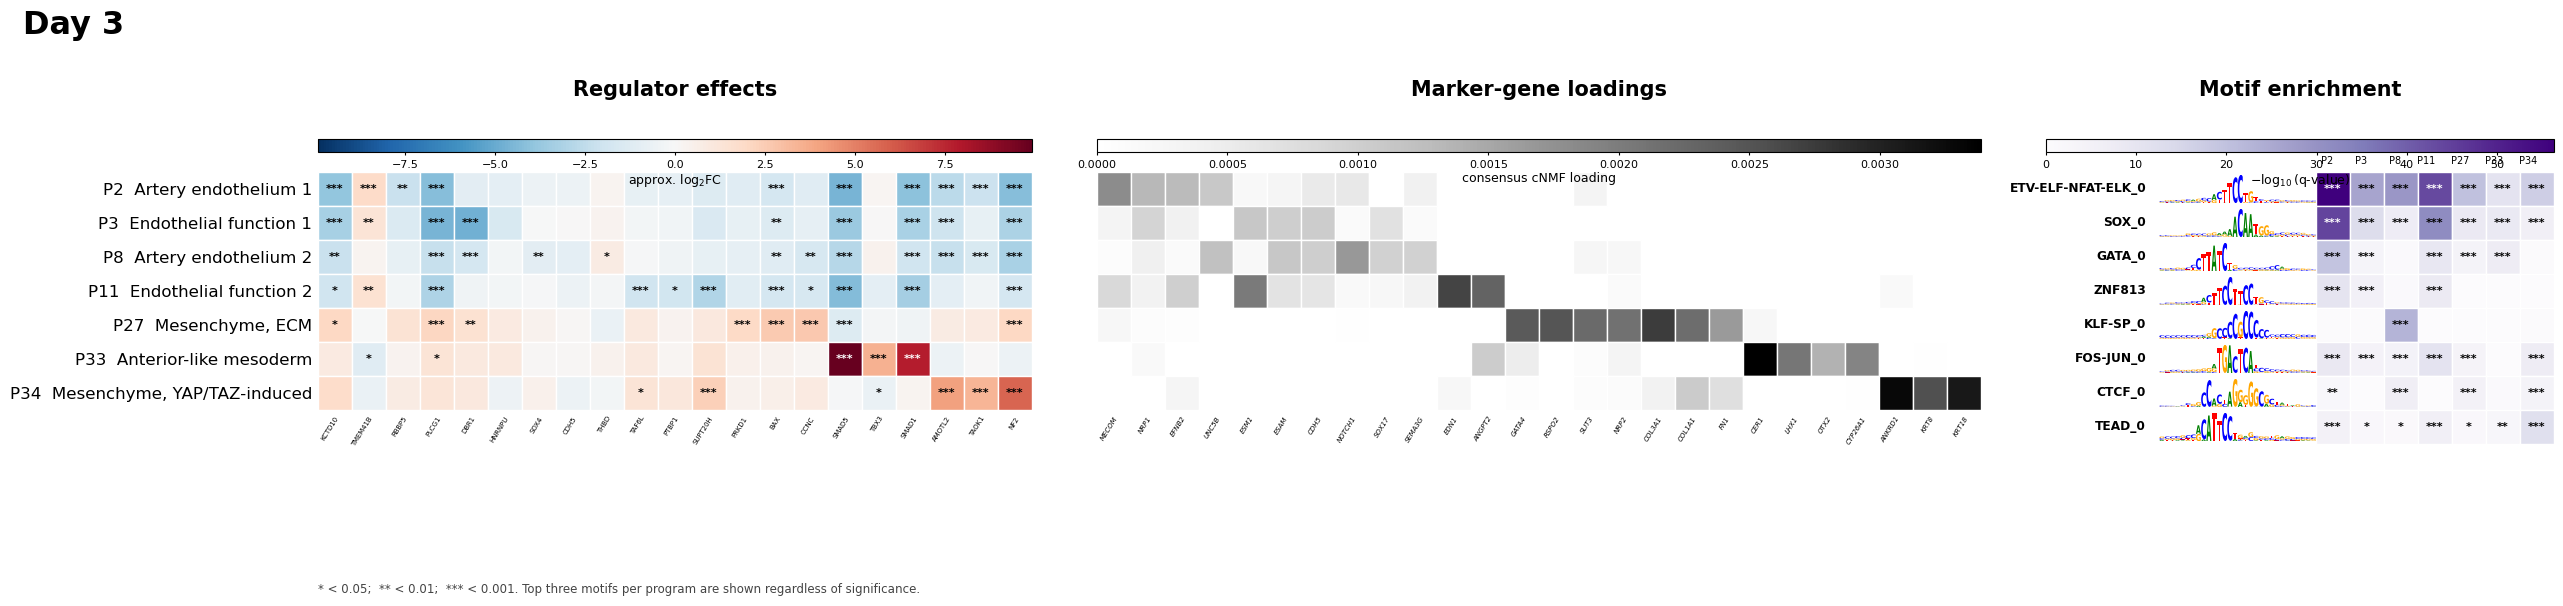

Saved D3:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3_motifs_as_rows.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3_motifs_as_rows.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_panel_D3_motifs_as_rows.png

Rendering combined D0-D3 figure with shared colorbars...


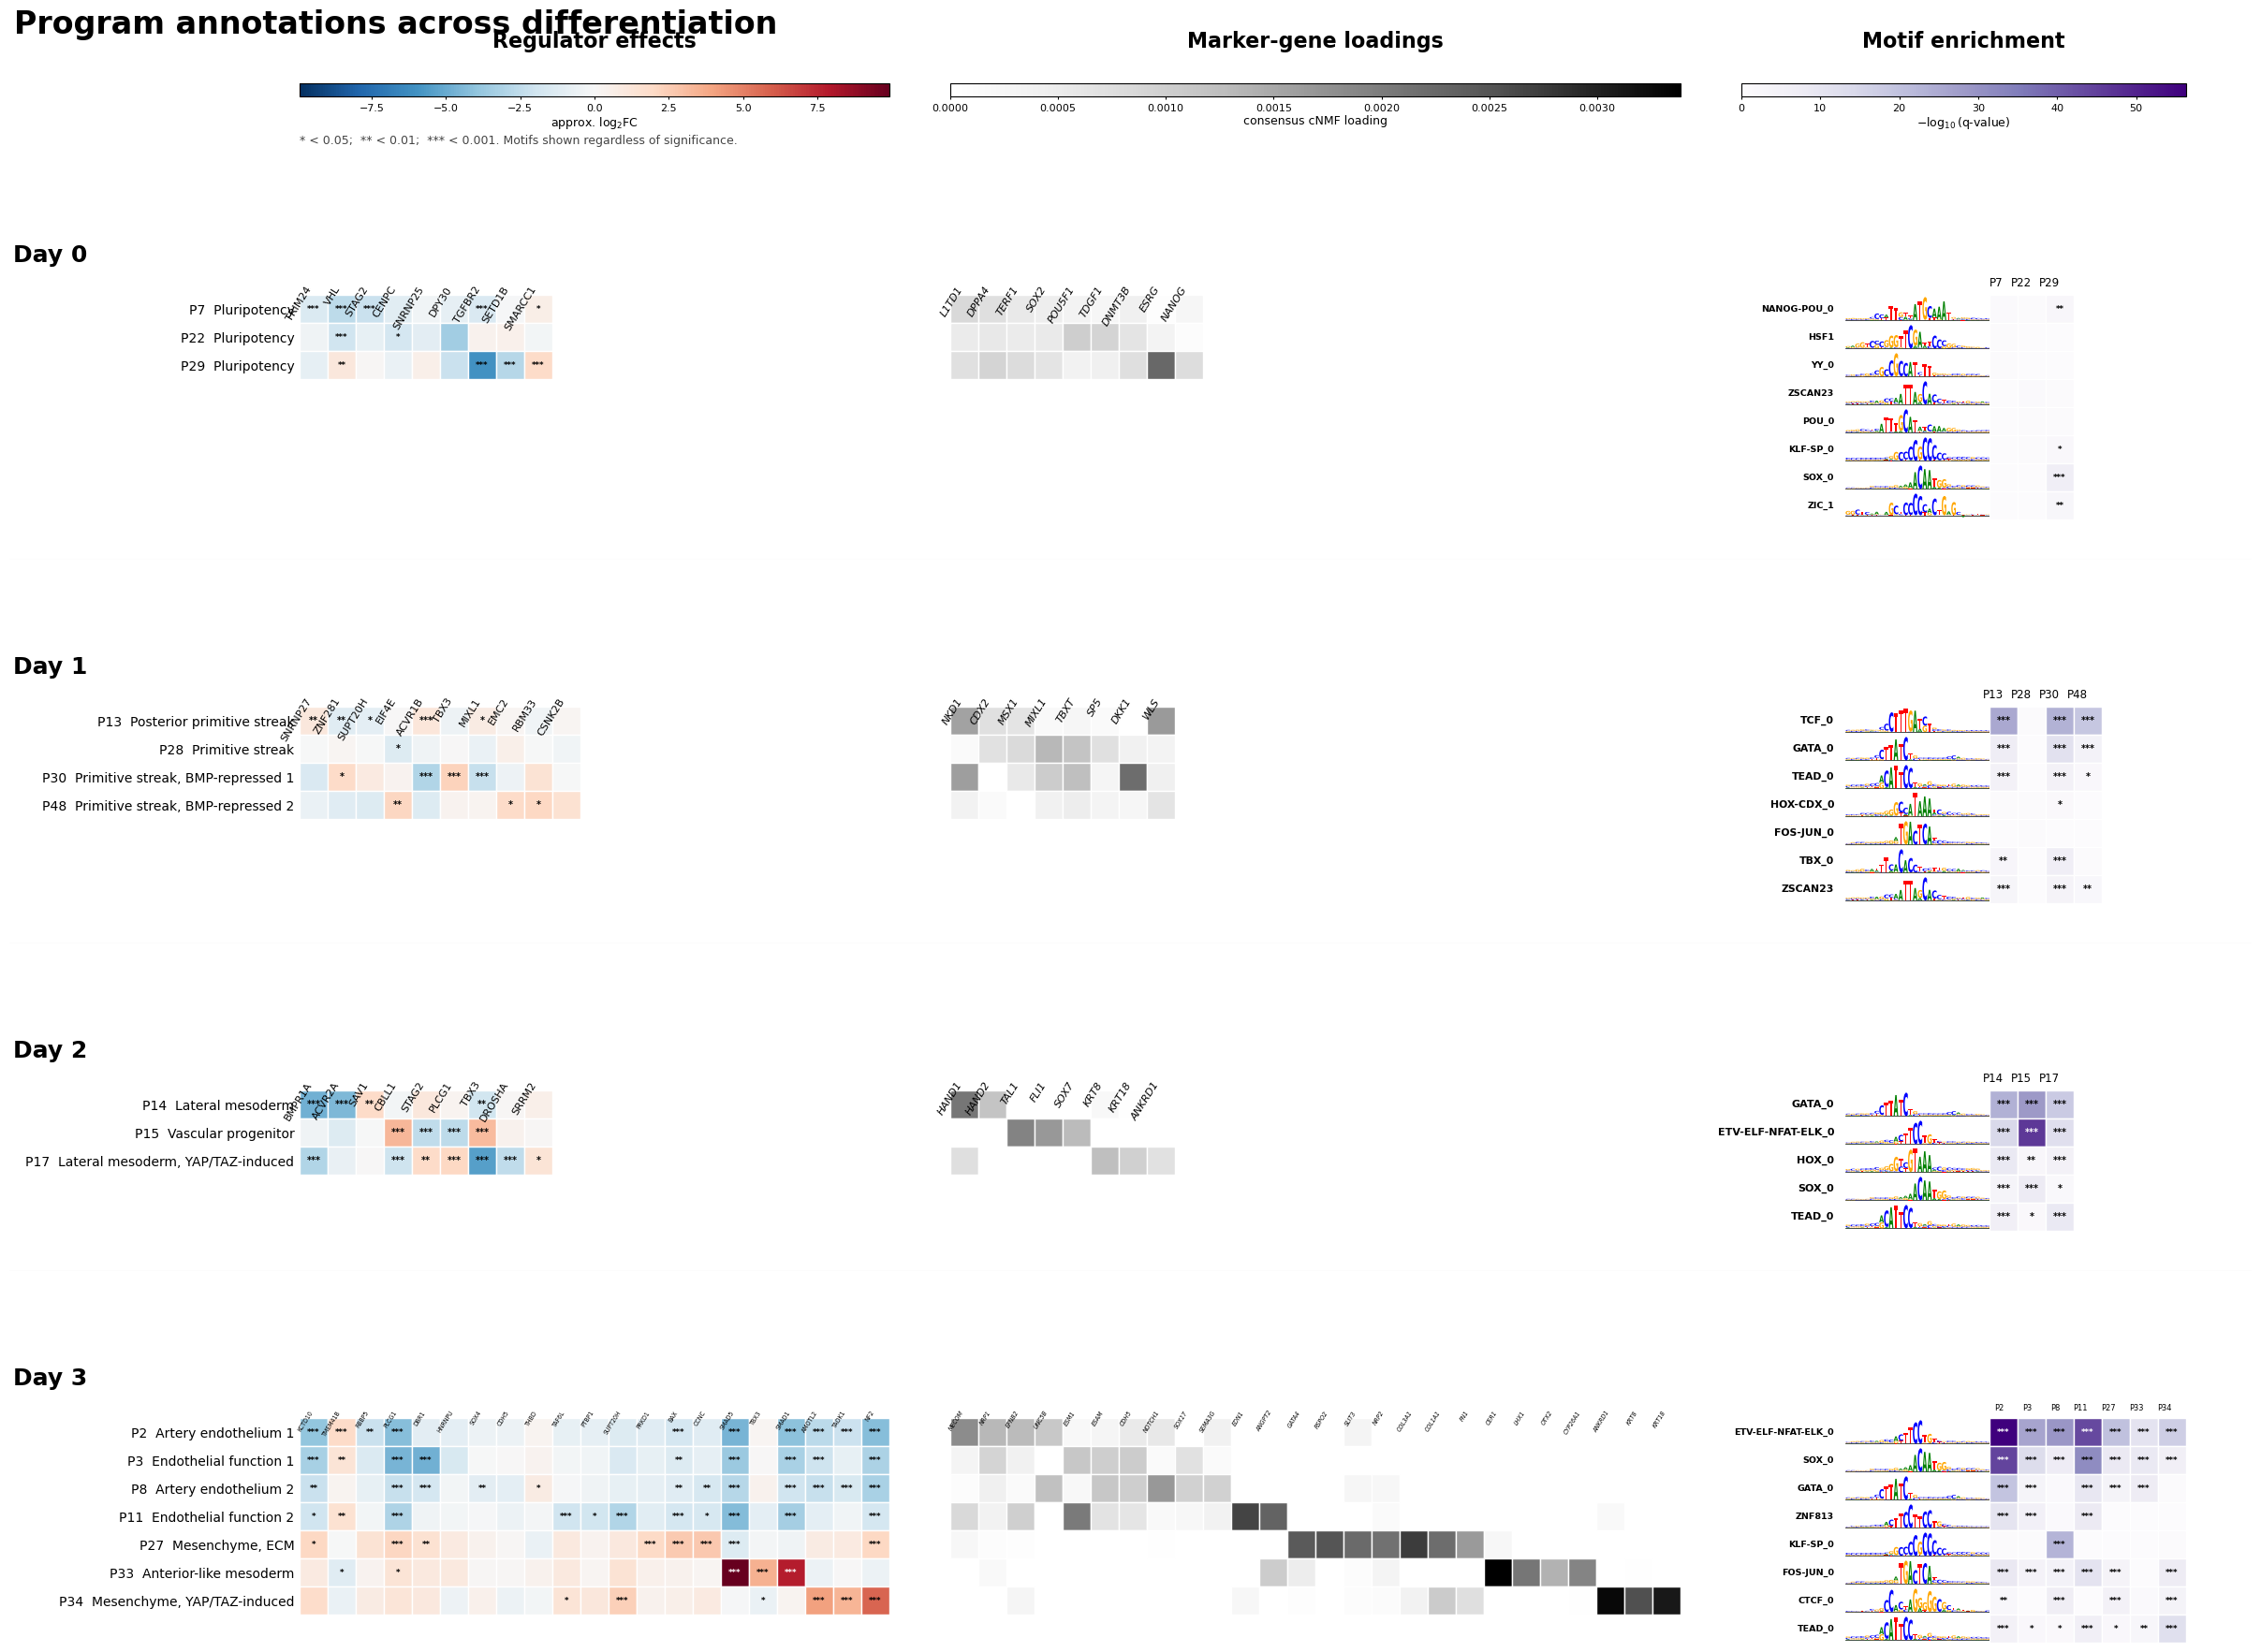

Saved combined figure:
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_D0_D1_D2_D3_combined_motifs_as_rows.svg
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_D0_D1_D2_D3_combined_motifs_as_rows.pdf
  /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/Program_annotation_D0_D1_D2_D3_combined_motifs_as_rows.png


In [6]:

# ============================================================
# RENDER PER-DAY PANELS AND COMBINED D0-D3 FIGURE
# ============================================================

if MAKE_PER_DAY_PANELS:
    print("Rendering per-day panels with motifs as rows...")

    for day in DAYS_TO_PLOT:
        if day not in day_packages:
            print(f"[skip] {day}: no package")
            continue

        outstem = make_day_panel_motifs_as_rows(
            day=day,
            day_pkg=day_packages[day],
            shared_scales=shared_scales,
        )

        print(f"Saved {day}:")
        print(" ", outstem.with_suffix(".svg"))
        print(" ", outstem.with_suffix(".pdf"))
        print(" ", outstem.with_suffix(".png"))


if MAKE_COMBINED_ALL_DAYS_FIGURE:
    print("\nRendering combined D0-D3 figure with shared colorbars...")

    combined_outstem = make_combined_all_days_figure(
        day_packages=day_packages,
        days=DAYS_TO_PLOT,
        shared_scales=shared_scales,
    )

    print("Saved combined figure:")
    print(" ", combined_outstem.with_suffix(".svg"))
    print(" ", combined_outstem.with_suffix(".pdf"))
    print(" ", combined_outstem.with_suffix(".png"))
